# 02 · XGBoost, el modelo de referencia

XGBoost es el estándar de la industria para datos tabulares, así que es la vara contra la que comparamos todo. Acá lo entrenamos, miramos cómo le va con los thin-file (ordena peor que con el resto, pero está bien calibrado) y guardamos su logit para cada solicitante.

- **Lee:** `outputs/datos_procesados.npz`, `outputs/ids_*.csv` y, para marcar quién es thin-file, `data/application_train.csv` y `data/bureau.csv`.
- **Guarda:** `outputs/preds/xgboost_calib.csv` y `outputs/preds/xgboost_test.csv` (un logit por solicitante).
- **En el informe:** este es el XGBoost de la Tabla 1, la Tabla 2 y las figuras 2, 4 y 5. Sus números finales se calculan en el 04.

In [3]:
# Bloque 1. Cargamos las matrices que armamos en el 01.
import numpy as np
import pandas as pd

datos=np.load("outputs/datos_procesados.npz")

X_train, y_train = datos["X_train"], datos["y_train"]
X_calib, y_calib = datos["X_calib"], datos["y_calib"]
X_test, y_test = datos["X_test"], datos["y_test"]

print(X_train.shape, X_calib.shape, X_test.shape)
print(y_train.mean(), y_calib.mean(), y_test.mean())

# Carga ok: 200 columnas (62 numéricas + 34 marcas de "faltaba" + 104 dummies) y la misma tasa de mora (~8,07%) en
# las tres partes.

(184506, 200) (30751, 200) (92254, 200)
0.08072908198107379 0.08074534161490683 0.08072278708782275


In [2]:
# Bloque 2. Un primer XGBoost (parámetros razonables, sin afinar) evaluado con validación cruzada de 3 folds SOLO en
# train. calib y test no se tocan acá.
# Cómo funciona XGBoost: arma árboles de decisión uno atrás del otro, y cada árbol nuevo se ajusta para corregir los
# errores que dejó el conjunto de los anteriores (gradient boosting). El resultado es un score de riesgo, pero NO una
# medida de qué tan lejos está el solicitante de los datos con los que aprendió: esa es justamente la pieza que le
# falta y que la SNGP sí tiene.
# AUC = probabilidad de que el modelo le asigne más riesgo a un moroso que a un buen pagador elegidos al azar.
# 0.5 = azar, 1 = perfecto. No depende de ningún umbral de corte, solo del orden.

from xgboost import XGBClassifier
from sklearn.model_selection import cross_val_score

modelo=XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=1)
# n_estimators: cuántos árboles; learning_rate: cuánto le hace caso cada árbol nuevo al error anterior;
# max_depth: profundidad máxima (cantidad de cortes) de cada árbol; subsample: qué fracción de observaciones ve cada
# árbol; colsample_bytree: qué fracción de columnas ve cada árbol; n_jobs: núcleos de la compu que usa.

aucs=cross_val_score(modelo, X_train, y_train, cv=3, scoring="roc_auc")
print(aucs, aucs.mean())

# AUC por fold = 0.755 / 0.762 / 0.752, media 0.756. Los folds se parecen entre sí (el modelo es estable) y el valor
# está en el rango habitual para Home Credit usando solo la tabla de solicitudes: el preprocesamiento funciona.

[0.7550096  0.76174763 0.75178765] 0.7561816253165238


In [3]:
# Bloque 3. Reconstruimos la marca thin_file para cada parte (train / calib / test), porque en este notebook solo
# tenemos X e y. thin_file = el cliente NO aparece en bureau.csv. Buscamos cada ID guardado en outputs/ids_*.csv, que
# está en el mismo orden que las filas de X: thin["train"][i] corresponde a la fila i de X_train.
# La necesitamos para medir el desempeño por grupo (thin-file contra el resto), que es el foco del proyecto.

import pandas as pd

df=pd.read_csv("data/application_train.csv", usecols=["SK_ID_CURR"])
bureau=pd.read_csv("data/bureau.csv", usecols=["SK_ID_CURR"])
df["thin_file"]=(~df["SK_ID_CURR"].isin(bureau["SK_ID_CURR"])).astype(int)

# set_index("SK_ID_CURR") usa el ID como nombre de fila, así que mapa es una tabla ID -> thin_file.
# mapa.loc[ids] busca esos IDs en el orden dado, y la marca queda alineada con las filas de X.

mapa=df.set_index("SK_ID_CURR")["thin_file"]

thin={}

for nombre in ["train","calib","test"]:
    ids=pd.read_csv(f"outputs/ids_{nombre}.csv")["SK_ID_CURR"]
    thin[nombre]=mapa.loc[ids].to_numpy()

for nombre in thin:
    print(nombre, len(thin[nombre]), thin[nombre].mean())

# Longitudes ok (184506 / 30751 / 92254) y ~14,3% de thin-file en las tres partes.

train 184506 0.14314981626613768
calib 30751 0.14314981626613768
test 92254 0.14314826457389382


In [ ]:
# Bloque 4. ¿Cómo le va a XGBoost con los thin-file? El AUC total (0.756) es un chequeo general, pero los thin-file
# son solo el 14% y un promedio puede esconder un peor desempeño en una minoría. Como la pregunta del proyecto es
# sobre ellos, medimos el AUC por grupo.
# cross_val_score devuelve una nota por fold (3 números); cross_val_predict, en cambio, devuelve la probabilidad de
# mora de cada cliente (184.506 números) predicha por el modelo que NO lo vio al entrenar ("out-of-fold"). Eso nos
# deja recortar por grupo.

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_auc_score

p_oof=cross_val_predict(modelo, X_train, y_train, cv=3, method='predict_proba')[:,1]
# predict_proba devuelve dos columnas (prob. de pagar y prob. de mora); como TARGET = 1 es mora, nos quedamos con [:,1]

t=thin["train"]   # la guardamos en t para no escribir thin["train"] todo el tiempo
print("AUC total:", roc_auc_score(y_train, p_oof))   # roc_auc_score(y real, score)
print("AUC thin_file:", roc_auc_score(y_train[t==1], p_oof[t==1]))
print("AUC resto:", roc_auc_score(y_train[t==0], p_oof[t==0]))
print("default thin_file:", y_train[t==1].mean(), "| del resto:", y_train[t==0].mean())

# AUC out-of-fold en train: total 0.756 | thin-file 0.733 | resto 0.758. Mora real: thin-file 10,1% contra 7,7%.
# O sea que XGBoost ordena peor a los thin-file (~2,5 puntos de AUC menos), que además son más riesgosos. Es
# consistente con la hipótesis del proyecto, pero no la prueba: falta ver la calibración.

AUC total: 0.7561204609321377
AUC thin_file: 0.7326872490406207
AUC resto: 0.7584811898140922
default thin_file: 0.10124185976071483 | del resto: 0.07730211140207724


In [5]:
# Calibración en promedio: ¿la probabilidad media que predice el modelo se parece a la mora real de cada grupo?

print("prob. media predicha thin-file:", p_oof[t==1].mean(), "| default real:", y_train[t==1].mean())
print("prob. media predicha resto:", p_oof[t==0].mean(), "| default real:", y_train[t==0].mean())

prob. media predicha thin-file: 0.09805743 | default real: 0.10124185976071483
prob. media predicha resto: 0.077688955 | default real: 0.07730211140207724


In [ ]:
# Thin-file: predice 9,8% contra 10,1% real; resto: 7,77% contra 7,73%. XGBoost está bien calibrado EN PROMEDIO en
# los dos grupos: no subestima el riesgo medio de los thin-file. La "sobreconfianza" de la hipótesis no se ve en la
# calibración media; lo que sí se ve es menos poder de ordenamiento (AUC) en thin-file.
# Ahora miramos lo mismo por deciles: ordenamos a cada grupo según la probabilidad predicha, lo cortamos en 10
# pedazos iguales y comparamos predicho contra real en cada pedazo.

tabla=pd.DataFrame({"p": p_oof, "y": y_train, "thin": t})

for grupo, nombre in [(0, "resto"), (1, "thin_file")]:   # primero el resto (0) y después los thin-file (1)
    sub=tabla[tabla["thin"]==grupo].copy()   # nos quedamos con las filas de ese grupo
    sub["decil"]=pd.qcut(sub["p"], 10, labels=False)   # decil de probabilidad predicha (0 = el 10% más seguro)
    resumen=sub.groupby("decil").agg(pred=("p","mean"), real=("y","mean"), n=("y","size"))
    print(nombre)
    print(resumen.round(3))

# En todos los deciles, de los dos grupos, la probabilidad predicha y la mora real casi coinciden: XGBoost está bien
# calibrado también decil por decil. Esto es lo que después aparece en la Tabla 1 como un ECE muy bajo (0,0039 en
# thin-file) y lo que explica que la "regla ingenua" casi cumpla con XGBoost (ver el 04).

resto
        pred   real      n
decil                     
0      0.013  0.012  15810
1      0.021  0.020  15809
2      0.028  0.027  15809
3      0.036  0.034  15810
4      0.045  0.043  15809
5      0.057  0.057  15809
6      0.073  0.074  15810
7      0.098  0.100  15809
8      0.140  0.141  15809
9      0.266  0.264  15810
thin_file
        pred   real     n
decil                    
0      0.019  0.016  2642
1      0.032  0.030  2641
2      0.043  0.043  2641
3      0.055  0.056  2641
4      0.067  0.072  2641
5      0.082  0.083  2641
6      0.101  0.113  2641
7      0.127  0.126  2641
8      0.170  0.178  2641
9      0.285  0.296  2642


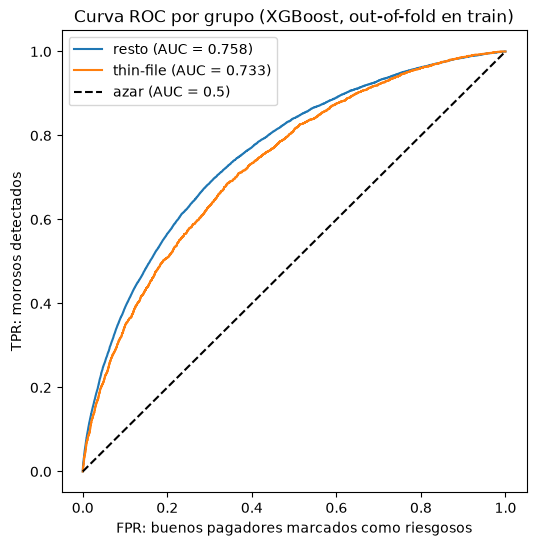

In [ ]:
# Qué nos deja esto: XGBoost está bien calibrado (en promedio y por deciles) en thin-file y en el resto, así que la
# hipótesis de "sobreconfianza" no se sostiene en la calibración. Lo que sí aparece es peor poder de ordenamiento en
# thin-file, que además son más riesgosos.
# Por qué importa para Conformal Selection: la garantía (que la proporción esperada de morosos entre los aprobados no
# pase de alfa) vale con cualquier modelo, pero CUÁNTOS créditos se aprueban con esa garantía depende de qué tan bien
# ordena el modelo. La pregunta pasa a ser: ¿un modelo sensible a la distancia ordena mejor a los thin-file y, con
# la misma garantía, aprueba a más?

# Curva ROC por grupo. Recordemos que el AUC es el área bajo esta curva: en el eje y, TPR (de los morosos reales,
# qué % marca el modelo como riesgosos) y en el eje x, FPR (de los que pagaron, qué % marca por error), para todos
# los umbrales de corte posibles. "Ordena peor" quiere decir que, a igual tasa de falsos positivos, detecta menos morosos.

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

plt.figure(figsize=(6, 6))
for grupo, nombre in [(0, "resto"), (1, "thin-file")]:
    fpr, tpr, _ = roc_curve(y_train[t == grupo], p_oof[t == grupo])
    auc = roc_auc_score(y_train[t == grupo], p_oof[t == grupo])
    plt.plot(fpr, tpr, label=f"{nombre} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="azar (AUC = 0.5)")
plt.xlabel("FPR: buenos pagadores marcados como riesgosos")
plt.ylabel("TPR: morosos detectados")
plt.title("Curva ROC por grupo (XGBoost, out-of-fold en train)")
plt.legend()
plt.show()

# La curva de thin-file queda siempre un poco por debajo de la del resto. Esta figura es solo para mirar; no va al informe.

In [8]:
# Bloque 5. Una regresión logística de control, con los mismos folds y la misma métrica. No se reporta: sirve para
# verificar que XGBoost le gana (si no, algo andaría mal en los datos o en el modelo) y para ver cuánto aportan las
# no linealidades.
from sklearn.linear_model import LogisticRegression

logit=LogisticRegression(max_iter=1000)

aucs_log=cross_val_score(logit, X_train, y_train, cv=3, scoring="roc_auc")

print(aucs_log, aucs_log.mean())

# AUC por fold = 0.746 / 0.755 / 0.744, media 0.748 contra 0.756 de XGBoost. XGBoost le gana por 0.8 puntos: el
# benchmark tiene sentido. Y la brecha es chica, o sea que la señal es en su mayor parte lineal; no esperamos que
# ningún modelo le saque mucho AUC a XGBoost. Lo que vamos a mirar es otra cosa: cuántos thin-file se aprueban con la
# misma garantía. Un resultado nulo también vale.

[0.74564628 0.75461172 0.74440428] 0.7482207592572929


In [9]:
# Bloque 6. Tuneo corto de XGBoost. Separamos un 15% de train como validación (calib y test quedan intactos) y usamos
# early stopping para elegir la cantidad de árboles (tope 2000, corta si pasan 100 sin mejorar). Probamos varias
# profundidades y comparamos el AUC de validación.

from sklearn.model_selection import train_test_split

X_fit, X_val, y_fit, y_val=train_test_split(X_train, y_train, test_size=0.15, random_state=42, stratify=y_train)

resultados={}   # profundidad -> (mejor cantidad de árboles, AUC de validación)

for depth in [3,4,5,6,8]:
    xgbtuned=XGBClassifier(n_estimators=2000,learning_rate=0.05, max_depth=depth, subsample=0.8, colsample_bytree=0.8,
                           eval_metric="auc",early_stopping_rounds=100, random_state=42, n_job=1)
    xgbtuned.fit(X_fit, y_fit, eval_set=[(X_val, y_val)], verbose=False)
    resultados[depth]=(xgbtuned.best_iteration, xgbtuned.best_score)

print(resultados)

# Los avisos de "n_job" son porque acá quedó escrito n_job en vez de n_jobs: XGBoost lo ignora y usa sus núcleos por
# defecto. No cambia el resultado, solo la velocidad.

c:\Users\maxim\OneDrive\Desktop\beyond-credit-score\.venv\Lib\site-packages\xgboost\callback.py:385: UserWarning: [22:00:21] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "n_job" } are not used.

  self.starting_round = model.num_boosted_rounds()
c:\Users\maxim\OneDrive\Desktop\beyond-credit-score\.venv\Lib\site-packages\xgboost\callback.py:385: UserWarning: [22:00:59] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "n_job" } are not used.

  self.starting_round = model.num_boosted_rounds()
c:\Users\maxim\OneDrive\Desktop\beyond-credit-score\.venv\Lib\site-packages\xgboost\callback.py:385: UserWarning: [22:01:18] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "n_job" } are not used.

  self.starting_round = model.num_boosted_rounds()
c:\Users\maxim\OneDrive\Desktop\beyond-credit-score\.venv\Lib\site-packages\xgboost\callback.py:385: UserWarning: [22:01:36] WARNING: C:\actions-

{3: (993, 0.7681077423137443), 4: (407, 0.7674844910293971), 5: (323, 0.7657346493581659), 6: (331, 0.7658853599075595), 8: (179, 0.7621417000079596)}


In [ ]:
# AUC de validación 0.7681 / 0.7675 / 0.7657 / 0.7659 / 0.7621 para profundidad 3 / 4 / 5 / 6 / 8 (con 993 / 407 /
# 323 / 331 / 179 árboles). Entre 3 y 6 la diferencia es chica (<0.003) y con 8 empeora. Nos quedamos con
# max_depth=4, que es lo que ya teníamos. El early stopping pedía ~400 árboles, algo más que los 300 del primer
# modelo; la diferencia de AUC es mínima y dejamos 300.
# Ojo: este AUC de validación (un solo corte de ~27.700 clientes) es más ruidoso que el de la validación cruzada;
# sirve para comparar profundidades entre sí, no como estimación precisa del AUC.

# Bloque 7. El modelo final: lo entrenamos con TODO train y predecimos sobre calib y test.

modelo_final=XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=1)

modelo_final.fit(X_train, y_train)   # aprende con todo train

# predict_proba solo necesita las características (X) de cada cliente; la y es justo lo que tiene que estimar sin
# verla. [:,1] = probabilidad de mora.
p_calib=modelo_final.predict_proba(X_calib)[:,1]
p_test=modelo_final.predict_proba(X_test)[:,1]

print(p_calib.shape, p_test.shape)

(30751,) (92254,)


In [11]:
# Bloque 8. Guardamos las predicciones del XGBoost final con un formato común a todos los modelos:
# SK_ID_CURR, thin_file, TARGET, logit (log(p/(1-p))) y var (0, porque XGBoost no tiene incertidumbre propia).
# Así el experimento conformal del 04 lee lo mismo para cualquier modelo, sin reentrenar nada. np.clip evita log(0).
# Recordatorio: desde el 03, el 10% "calib" pasa a ser VALIDACIÓN y el 30% "test" es el POOL del experimento; los
# nombres de los archivos (xgboost_calib / xgboost_test) quedaron con los nombres de esta primera etapa.

import os
os.makedirs("outputs/preds", exist_ok=True)

for nombre, p, y in [("calib", p_calib, y_calib), ("test", p_test, y_test)]:
    ids = pd.read_csv(f"outputs/ids_{nombre}.csv")["SK_ID_CURR"]
    p = np.clip(p, 1e-6, 1 - 1e-6)
    tabla = pd.DataFrame({"SK_ID_CURR": ids, "thin_file": thin[nombre], "TARGET": y,
                          "logit": np.log(p / (1 - p)), "var": 0.0})
    tabla.to_csv(f"outputs/preds/xgboost_{nombre}.csv", index=False)
    print(nombre, tabla.shape)

print(tabla.head())

# Guardados outputs/preds/xgboost_calib.csv (30751 filas) y xgboost_test.csv (92254). En el pool, este XGBoost tiene
# AUC thin-file 0,7203 (Tabla 1, se calcula en el 04).

calib (30751, 5)
test (92254, 5)
   SK_ID_CURR  thin_file  TARGET     logit  var
0      253614          0       0 -3.559002  0.0
1      116431          0       1 -1.288220  0.0
2      115721          0       0 -4.114257  0.0
3      344025          0       0 -2.559443  0.0
4      335621          1       0 -2.489954  0.0
